# Doing it in the real world: full-wave simulation and GPU beamforming

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/patrickmineault/fus/blob/main/06%20-%20Full-Wave%20Simulation%20and%20GPU%20Beamforming.ipynb)

In notebooks 1-3, we built functional ultrasound from scratch: we propagated waves, formed images with delay-and-sum, and turned the motion of red blood cells into Power Doppler. To keep the code legible, we took some shortcuts along the way:

| Notebook | Shortcut | What it leaves out |
|---|---|---|
| 1 | Angular spectrum method: one frequency, the same medium everywhere | Reflection and refraction where the medium changes, e.g. at the skull |
| 2 | Every scatterer echoes independently, along straight rays traveling at 1540 m/s | Echoes of echoes (reverberation), and distortion when the speed of sound isn't 1540 m/s (aberration) |
| 2-3 | Delay-and-sum on the CPU with Numba | Speed: an fUS scanner forms hundreds of images per second |

In this notebook, we'll swap each shortcut for a tool used in practice:

1. **Full-wave simulation.** We'll run a phantom like notebook 2's through [k-Wave](http://www.k-wave.org/), using its Python version [k-wave-python](https://github.com/waltsims/k-wave-python), check that it agrees with our simple model, then add a skull-like layer and see what our model was missing.
2. **GPU beamforming.** We'll beamform the simulated data with [vbeam](https://github.com/magnusdk/vbeam) and [mach](https://github.com/Forest-Neurotech/mach), check that they match our Numba delay-and-sum, and benchmark them.
3. **A map of the ecosystem**: which tool to reach for, and when.

**Running this notebook.** It's set up for Google Colab with a GPU (*Runtime → Change runtime type → T4 GPU*), and falls back to the CPU when there's no GPU. On an 8-core laptop without a GPU, it takes about 8 minutes, most of it spent in k-Wave.

On Colab, the next cell installs the packages and downloads the helper module from notebooks 2-3. If pip replaces a package that Colab had already loaded, Colab will ask you to restart the session; do so, and run the notebook again.

In [1]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "k-wave-python", "vbeam", "mach-beamform"], check=True)
    import urllib.request

    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/patrickmineault/fus/main/src/ultrasound_processing.py",
        "ultrasound_processing.py",
    )

In [2]:
import time

import jax
import kwave
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal
from kwave.kgrid import kWaveGrid
from kwave.kmedium import kWaveMedium
from kwave.ksensor import kSensor
from kwave.ksource import kSource
from kwave.kspaceFirstOrder import kspaceFirstOrder
from tqdm import tqdm

from ultrasound_processing import (
    SimParams,
    beamform_das_vectorized,
    build_das_sparse_matrix,
    make_image_grid,
    simulate_forward_channels_vectorized,
)

try:
    import cupy as cp

    GPU = cp.cuda.runtime.getDeviceCount() > 0
except Exception:  # no CuPy, or no CUDA driver
    GPU = False
print(f"CUDA GPU available: {GPU}")
print(f"JAX devices: {jax.devices()}")

CUDA GPU available: True
JAX devices: [CudaDevice(id=0)]


# Full-wave simulation with k-Wave

In notebook 1, we solved the wave equation in Fourier space, for a single frequency, in a medium with the same properties everywhere. That notebook ended with the equation that heavier simulators solve, where the speed of sound changes through space. k-Wave solves an equivalent set of first-order equations for the particle velocity $\mathbf{u}$, the density $\rho$ and the pressure $p$:

$$\frac{\partial \mathbf{u}}{\partial t} = -\frac{1}{\rho_0(\mathbf{x})} \nabla p, \qquad \frac{\partial \rho}{\partial t} = -\rho_0(\mathbf{x}) \nabla \cdot \mathbf{u}, \qquad p = c_0(\mathbf{x})^2 \rho + \text{absorption terms}$$

When the sound speed $c_0$ and the ambient density $\rho_0$ are constant, these combine into the wave equation of notebook 1. k-Wave's method is *pseudospectral*: it computes spatial derivatives with FFTs, the same trick as the angular spectrum approach, but at every time step, on a grid where the medium can change from one point to the next. Two consequences:

* **The grid can be coarse.** Derivatives computed with FFTs are exact up to the grid's Nyquist frequency, so a few grid points per wavelength suffice, where finite-difference methods typically need 10 or more. k-Wave also corrects its time stepping in k-space, which makes it exact in a homogeneous medium.
* **The edges need care.** FFTs treat the grid as periodic, so a wave leaving one side would come back on the other. k-Wave surrounds the grid with a *perfectly matched layer* (PML) that absorbs outgoing waves.

The cost is the number of grid points times the number of time steps. For the simulation to be stable and accurate, a wave shouldn't cross more than a fraction of a grid cell per time step (k-Wave's default is $c_{max} \Delta t / \Delta x = 0.3$, the CFL number), so the fastest material in the medium sets the time step. A skull, where sound travels almost twice as fast as in the brain, almost doubles the number of time steps.

Let's set up a grid for the probe of notebooks 2-3: 128 elements with a 100 μm pitch, transmitting at 15 MHz. We'll use 3 grid points per element.

In [3]:
c0, rho0 = 1540.0, 1000.0  # brain-like background
c_bone, rho_bone = 2800.0, 1850.0  # skull-like layer
f0, cycles = 15e6, 14  # transmit frequency and burst length, as in notebook 2
pitch, n_elem = 100e-6, 128  # the probe of notebooks 2-3

dx = pitch / 3
nz, nx = 312, 408
pml = 20  # absorbing layer, added around the grid
x_grid = (np.arange(nx) - (nx - 1) / 2) * dx
z_grid = np.arange(nz) * dx
elem_pos = (np.arange(n_elem) - (n_elem - 1) / 2) * pitch

print(f"Grid spacing: {dx * 1e6:.1f} μm")
print(f"Points per wavelength: {c0 / f0 / dx:.1f} in tissue, {c_bone / f0 / dx:.1f} in bone")
print(f"Domain: {nx * dx * 1e3:.1f} mm wide x {nz * dx * 1e3:.1f} mm deep, {(nz + 2 * pml) * (nx + 2 * pml):,} grid points")

Grid spacing: 33.3 μm
Points per wavelength: 3.1 in tissue, 5.6 in bone
Domain: 13.6 mm wide x 10.4 mm deep, 157,696 grid points


## A phantom, and a skull

We'll reuse notebook 2's recipe, scaled down to fit on a laptop: randomly placed point scatterers at the same density as in notebook 2, four anechoic cysts with radii of 0.4-1 mm, and six bright point targets ("wires"), the standard way to measure an imaging system's resolution. The field is 10 mm deep, rather than 40 mm.

In k-Wave, a scatterer isn't a point: it's a small change in the medium. We make each scatterer a single grid point whose speed of sound is 2% higher than the background, and each wire a row of three grid points 20% faster than the background. These small changes reflect a tiny fraction of the incoming wave, like the point scatterers of notebook 2. To compare the two models fairly, we snap the scatterers to grid points and use the same positions in both.

In [4]:
rng = np.random.default_rng(0)
density = 16000 / (14e-3 * 30e-3)  # scatterers per m², as in notebook 2
x_span, z_span = (-6.4e-3, 6.4e-3), (2.5e-3, 10e-3)
n_scat = int(density * (x_span[1] - x_span[0]) * (z_span[1] - z_span[0]))
xs = rng.uniform(*x_span, n_scat)
zs = rng.uniform(*z_span, n_scat)

cysts = [(-3.9e-3, 6.5e-3, 0.4e-3), (-1.3e-3, 6.5e-3, 0.6e-3), (1.3e-3, 6.5e-3, 0.8e-3), (3.9e-3, 6.5e-3, 1.0e-3)]
outside = np.ones(n_scat, bool)
for cx, cz, r in cysts:
    outside &= (xs - cx) ** 2 + (zs - cz) ** 2 > r**2
xs, zs, amp = xs[outside], zs[outside], np.ones(outside.sum())

wires = [(wx, wz) for wz in (4e-3, 8.5e-3) for wx in (-3e-3, 0.0, 3e-3)]
for wx, wz in wires:
    xs = np.append(xs, wx + np.array([-dx, 0, dx]))
    zs = np.append(zs, [wz] * 3)
    amp = np.append(amp, [10.0] * 3)

# Snap to the grid
ix = np.rint(xs / dx + (nx - 1) / 2).astype(int)
iz = np.rint(zs / dx).astype(int)
xs, zs = x_grid[ix], z_grid[iz]

c_tissue = np.full((nz, nx), c0)
np.add.at(c_tissue, (iz, ix), 0.02 * c0 * amp)
print(f"{len(xs):,} scatterers")

3,411 scatterers


Now for the skull. We place an uneven layer 1 mm below the probe (the gap stands for the coupling gel), 0.4-0.8 mm thick, with a sound speed of 2800 m/s and a density of 1850 kg/m³, close to those of bone. That's about as thick as a rodent's skull; a primate's skull is several millimeters thick. We'll treat it as a fluid, which ignores the shear waves that real bone carries, and give it the same absorption as the tissue, which underestimates how much bone absorbs and scatters at 15 MHz. Both simplifications are kind to the skull: we're isolating the effect of its speed of sound and density.

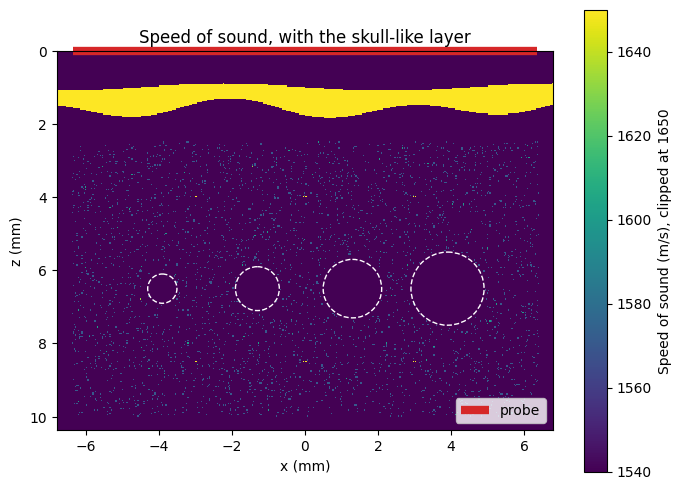

In [5]:
X, Z = np.meshgrid(x_grid, z_grid)
skull_top = 1.0e-3 + 0.1e-3 * np.sin(2 * np.pi * x_grid / 9e-3)
skull_thickness = 0.6e-3 + 0.2e-3 * np.sin(2 * np.pi * x_grid / 5e-3 + 1)
skull = (Z >= skull_top) & (Z <= skull_top + skull_thickness)

c_skull = np.where(skull, c_bone, c_tissue)
rho_skull = np.where(skull, rho_bone, rho0)

extent = [x_grid[0] * 1e3, x_grid[-1] * 1e3, z_grid[-1] * 1e3, z_grid[0] * 1e3]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(c_skull, extent=extent, cmap="viridis", vmin=c0, vmax=1650, interpolation="nearest")
ax.plot(elem_pos[[0, -1]] * 1e3, [0, 0], color="C3", linewidth=6, solid_capstyle="butt", label="probe", clip_on=False)
for cx, cz, r in cysts:
    ax.add_patch(plt.Circle((cx * 1e3, cz * 1e3), r * 1e3, fill=False, color="w", linestyle="--"))
ax.set_xlabel("x (mm)")
ax.set_ylabel("z (mm)")
ax.set_title("Speed of sound, with the skull-like layer")
ax.legend(loc="lower right")
plt.colorbar(im, ax=ax, label="Speed of sound (m/s), clipped at 1650")
plt.show()

## Running k-Wave

The probe is a row of grid points along the top of the grid. To send a plane wave, we drive each point with the same burst as in notebook 2 (14 cycles at 15 MHz under a Hann window), delayed to tilt the wavefront by the steering angle $\beta$. The same points then record the pressure, and each element averages its 3 grid points.

k-wave-python has two solvers: a pure NumPy/CuPy one, which runs on the GPU when CuPy is installed, and an interface to k-Wave's compiled C++ code. On a CPU, the C++ solver is about 20 times faster, so we use it when there's no GPU.

One subtlety. k-Wave's k-space correction makes the time stepping exact for one *reference* sound speed; waves traveling at other speeds come out slightly too slow. By default, the reference is the fastest speed in the grid. With the skull in place, that's the bone, and pulses in the tissue would travel about 3% too slowly: enough to push the deepest structures in our images about 0.3 mm too deep, and to blur them. We want the tissue's speed as the reference instead, which is allowed as long as the time step stays small enough for the simulation to be stable (it does here). MATLAB k-Wave exposes this as `medium.sound_speed_ref`. k-wave-python 0.6.2 accepts the setting but ignores it, so we patch both solvers to honor it.

In [6]:
import h5py
from kwave.solvers.cpp_simulation import CppSimulation
from kwave.solvers.kspace_solver import Simulation

# Keep the original methods, even if this cell runs twice
_prepare = getattr(CppSimulation.prepare, "original", CppSimulation.prepare)
_setup_pml = getattr(Simulation._setup_pml, "original", Simulation._setup_pml)


def prepare(self, data_path=None):
    """C++ solver: overwrite the reference sound speed in the input file it writes."""
    input_file, output_file = _prepare(self, data_path)
    if self.medium.sound_speed_ref is not None:
        with h5py.File(input_file, "r+") as f:
            f["c_ref"][...] = self.medium.sound_speed_ref
    return input_file, output_file


def setup_pml(self):
    """NumPy/CuPy solver: replace the reference before the operators that use it are built."""
    if self.medium.sound_speed_ref is not None:
        self.c_ref = float(self.medium.sound_speed_ref)
    _setup_pml(self)


prepare.original, setup_pml.original = _prepare, _setup_pml
CppSimulation.prepare, Simulation._setup_pml = prepare, setup_pml

In [7]:
CPP_BINARY = kwave.BINARY_PATH / "kspaceFirstOrder-omp.exe" if kwave.PLATFORM == "windows" else None


def run_kwave(c, rho, source, sensor_mask, t):
    """Simulate on the (nz, nx) grid for times t; return the pressure at sensor_mask, shape (n_sensor, n_times)."""
    kgrid = kWaveGrid([nz, nx], [dx, dx])
    kgrid.setTime(len(t), t[1] - t[0])
    # k-Wave's absorption follows a power law alpha0 * f**y with y != 1; we pick y = 1.5 and choose
    # alpha0 so the absorption at 15 MHz matches notebook 2's 0.58 dB/cm/MHz.
    medium = kWaveMedium(sound_speed=c, density=rho, alpha_coeff=0.58 * 15 / 15**1.5, alpha_power=1.5,
                         sound_speed_ref=c0)
    kwargs = dict(pml_size=pml, quiet=True)
    if GPU:
        out = kspaceFirstOrder(kgrid, medium, source, kSensor(sensor_mask), backend="python", device="gpu",
                               dtype=np.float32, **kwargs)
        return out["p"]
    # k-wave-python 0.6.2 looks for the wrong file name on Windows, so we point it to the binary
    out = kspaceFirstOrder(kgrid, medium, source, kSensor(sensor_mask), backend="cpp", device="cpu",
                           binary_path=CPP_BINARY, **kwargs)
    # The C++ solver returns (time, sensor), with sensors in column-major order
    rank = np.argsort(np.argsort(np.ravel_multi_index(np.nonzero(sensor_mask), sensor_mask.shape, order="F")))
    return out["p"].T[rank]


def time_axis(c, t_end, cfl=0.3):
    dt = cfl * dx / c.max()
    return np.arange(int(np.ceil(t_end / dt))) * dt


probe = np.zeros((nz, nx), bool)
first = (nx - 3 * n_elem) // 2
probe[0, first : first + 3 * n_elem] = True
x_probe = x_grid[probe[0]]


def burst(t):
    """Hann-windowed burst, as in notebook 2."""
    T = cycles / f0
    return np.where((t >= 0) & (t <= T), np.sin(np.pi * t / T) ** 2 * np.sin(2 * np.pi * f0 * t), 0.0)


def plane_wave_source(beta, t):
    """Fire each probe point with a delay that tilts the wavefront by beta.

    Also returns the time at which the center of the pulse passes through x = 0, z = 0.
    """
    x_first = x_probe.min() if beta >= 0 else x_probe.max()
    delays = (x_probe - x_first) * np.sin(beta) / c0
    source = kSource()
    source.p_mask = probe
    source.p = burst(t[None, :] - delays[:, None])
    return source, -x_first * np.sin(beta) / c0 + cycles / f0 / 2

Before forming any images, let's watch a plane wave go through the skull. We record the pressure in a 6 mm × 5 mm window under the middle of the probe.

In [8]:
t_snap = time_axis(c_skull, 3e-6)
source, _ = plane_wave_source(0.0, t_snap)
window = np.zeros((nz, nx), bool)
win_z, win_x = slice(0, 150), slice(nx // 2 - 90, nx // 2 + 90)
window[win_z, win_x] = True

t1 = time.perf_counter()
p_window = run_kwave(c_skull, rho_skull, source, window, t_snap).reshape(150, 180, -1)
print(f"{len(t_snap)} time steps in {time.perf_counter() - t1:.0f} s")

840 time steps in 3 s


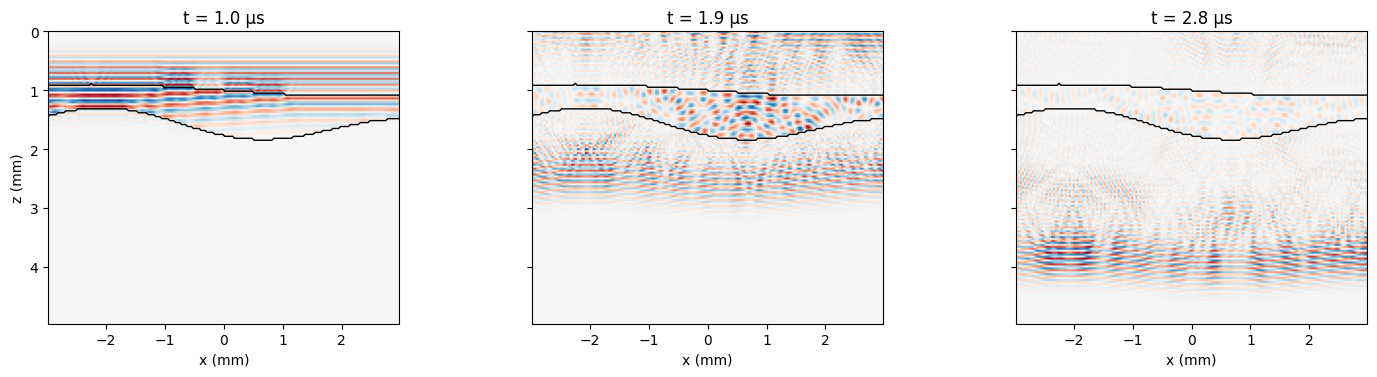

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
win_extent = [x_grid[win_x][0] * 1e3, x_grid[win_x][-1] * 1e3, z_grid[win_z][-1] * 1e3, z_grid[win_z][0] * 1e3]
for ax, t_show in zip(axes, [1.0e-6, 1.9e-6, 2.8e-6]):
    k = np.argmin(np.abs(t_snap - t_show))
    vmax = np.abs(p_window[10:, :, k]).max()  # each panel has its own color scale
    ax.imshow(p_window[:, :, k], extent=win_extent, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.contour(x_grid[win_x] * 1e3, z_grid[win_z] * 1e3, skull[win_z, win_x], levels=[0.5], colors="k", linewidths=1)
    ax.set_title(f"t = {t_snap[k] * 1e6:.1f} μs")
    ax.set_xlabel("x (mm)")
axes[0].set_ylabel("z (mm)")
plt.tight_layout()
plt.show()

(Each panel has its own color scale.) Three things happen at once, none of which the angular spectrum method of notebook 1 can capture:

* **Reflection.** About half of the incoming pressure bounces off the top of the skull, because bone's acoustic impedance ($\rho c$) is more than three times the tissue's. The reflected wave heads back to the probe.
* **Aberration.** Sound travels faster in bone, so the wavefront comes out ahead where the skull is thicker. The flat plane wave leaves the skull bumpy.
* **Reverberation.** Part of the wave bounces back and forth inside the skull, sending trailing copies of the pulse into the brain. (A real probe also reflects sound, which adds reverberations between the probe and the skull; our simulated probe is transparent.)

## Channel data

Now let's simulate what the probe records. We'll use the 5 steering angles (-6° to 6°) that Griggs et al. (2025) used for the monkey data of notebook 5, and simulate each angle twice: without the skull, then with it. We record until echoes from the bottom of the field have reached most of the probe.

As in notebook 2, we turn the recorded (real) RF signals into complex IQ signals: we take the analytic signal with a Hilbert transform and demodulate it by the carrier frequency. We then resample the IQ signals at 60 MHz, on a time axis where $t = 0$ is the moment the center of the transmitted pulse passes $x = 0, z = 0$, which is the convention our delay-and-sum code uses. Outside the recording, we set the signals to zero.

In [10]:
angles_deg = [-6.0, -3.0, 0.0, 3.0, 6.0]
betas = np.deg2rad(angles_deg)
fs = 60e6
z_max = z_grid[-1]
t_end = (z_max + np.hypot(z_max, 6.4e-3)) / c0 + cycles / f0 + n_elem * pitch * np.sin(betas.max()) / c0
# Long enough for every delay in the image, from the deepest pixel to the farthest element
times = np.arange(0, (z_max + np.hypot(z_max, 2 * 6.4e-3)) / c0, 1 / fs)


def to_iq(rf, t):
    iq = scipy.signal.hilbert(rf, axis=-1) * np.exp(-2j * np.pi * f0 * t)
    return np.array([np.interp(times, t, channel, left=0, right=0) for channel in iq])


def simulate_channels(c, rho):
    t = time_axis(c, t_end)
    iq = []
    for beta in tqdm(betas):
        source, t_origin = plane_wave_source(beta, t)
        p = run_kwave(c, rho, source, probe, t)
        rf = p.reshape(n_elem, 3, -1).mean(axis=1)
        iq.append(to_iq(rf, t - t_origin))
    return np.array(iq)


t1 = time.perf_counter()
iq_tissue = simulate_channels(c_tissue, rho0)
iq_skull = simulate_channels(c_skull, rho_skull)
print(f"Channel data {iq_tissue.shape} (angles, elements, samples), simulated in {time.perf_counter() - t1:.0f} s")

100%|██████████| 5/5 [01:06<00:00, 13.20s/it]

Channel data (5, 128, 1046) (angles, elements, samples), simulated in 126 s


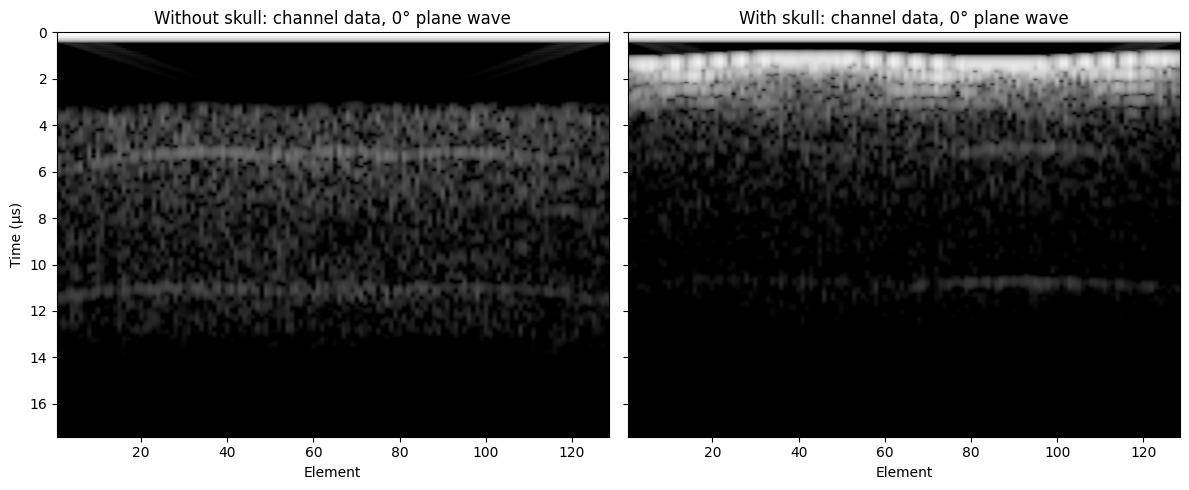

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ref = np.abs(iq_tissue[2]).max()
for ax, iq, title in [(axes[0], iq_tissue, "Without skull"), (axes[1], iq_skull, "With skull")]:
    ax.imshow(20 * np.log10(np.abs(iq[2]).T / ref + 1e-6), aspect="auto", cmap="gray", vmin=-60, vmax=0,
              extent=[0.5, n_elem + 0.5, times[-1] * 1e6, times[0] * 1e6])
    ax.set_xlabel("Element")
    ax.set_title(f"{title}: channel data, 0° plane wave")
axes[0].set_ylabel("Time (μs)")
plt.tight_layout()
plt.show()

Without the skull (left), each wire draws a hyperbola, as in notebook 2, on top of the speckle. With the skull (right), the strongest signals come from the skull itself in the first few microseconds, followed by a train of weaker copies from the reverberations, and the wire hyperbolas are wobbly and fainter.

## Images

Now we beamform both datasets with the Numba delay-and-sum from notebooks 2-3, and compare them with notebook 2's model, simulated for the same scatterers. Notebook 2's pulse starts at the echo time, where k-Wave's is centered on it, so we shift the model's time axis by half a pulse.

In [12]:
x_img, z_img, _, _ = make_image_grid((-6.4e-3, 6.4e-3), (0.5e-3, 10e-3), 0.05e-3, 0.05e-3)
omega = 2 * np.pi * f0
alpha = 0.58 * (f0 / 1e6) * 100 / 8.686  # absorption in Np/m, for time-gain compensation
img_tissue = beamform_das_vectorized(iq_tissue, times, elem_pos, x_img, z_img, c0, betas, omega, alpha)
img_skull = beamform_das_vectorized(iq_skull, times, elem_pos, x_img, z_img, c0, betas, omega, alpha)

P = SimParams(fs=fs, angles_deg=tuple(angles_deg), x_span=x_span, z_span=z_span)
Y, t_model, elem_model, _, _, s_env = simulate_forward_channels_vectorized(P, np.column_stack([xs, zs]), amp)
t_model = t_model - (len(s_env) - 1) / 2 / fs
img_model = beamform_das_vectorized(Y, t_model, elem_model, x_img, z_img, c0, betas, omega, alpha)

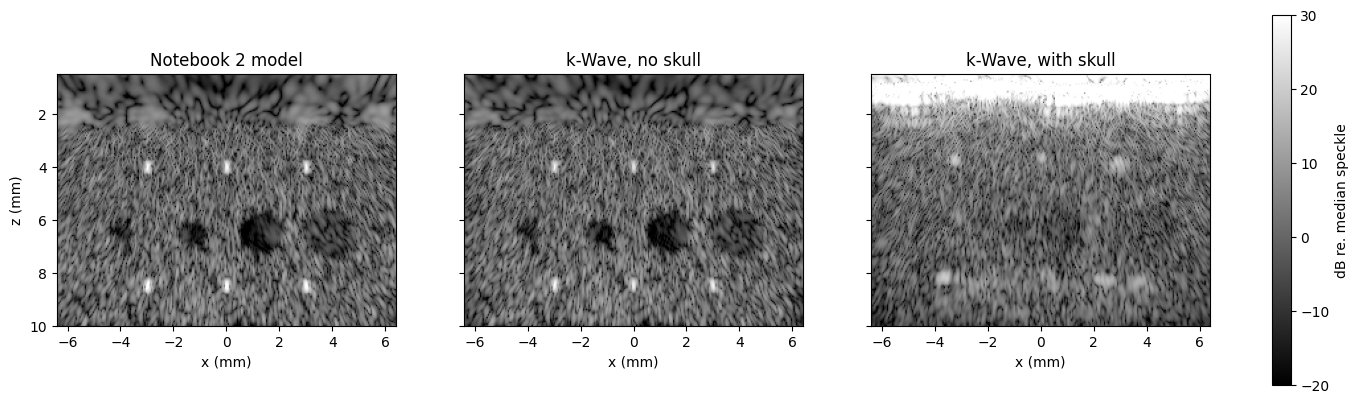

Correlation of the speckle with notebook 2's model: 0.93 without the skull, 0.08 with it


In [13]:
speckle = z_img > z_span[0]  # rows below the skull's reverberations, where the scatterers are
images = {"Notebook 2 model": img_model, "k-Wave, no skull": img_tissue, "k-Wave, with skull": img_skull}
envelopes = {name: np.abs(img) / np.median(np.abs(img[speckle])) for name, img in images.items()}

img_extent = [x_img[0] * 1e3, x_img[-1] * 1e3, z_img[-1] * 1e3, z_img[0] * 1e3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (name, env) in zip(axes, envelopes.items()):
    im = ax.imshow(20 * np.log10(env + 1e-6), extent=img_extent, cmap="gray", vmin=-20, vmax=30)
    ax.set_title(name)
    ax.set_xlabel("x (mm)")
axes[0].set_ylabel("z (mm)")
plt.colorbar(im, ax=axes, label="dB re. median speckle", fraction=0.02)
plt.show()

r_model = np.corrcoef(envelopes["Notebook 2 model"][speckle].ravel(), envelopes["k-Wave, no skull"][speckle].ravel())[0, 1]
r_skull = np.corrcoef(envelopes["Notebook 2 model"][speckle].ravel(), envelopes["k-Wave, with skull"][speckle].ravel())[0, 1]
print(f"Correlation of the speckle with notebook 2's model: {r_model:.2f} without the skull, {r_skull:.2f} with it")

Without the skull, the full-wave simulation and notebook 2's model don't just look alike: they produce the *same speckle pattern*, grain by grain. That's a strong check on both. The speckle is an interference pattern, so it only matches if the two simulations agree on the phase of every echo. The remaining differences come from effects the simple model leaves out, such as the waves diffracting off the edges of the finite probe.

So for imaging in soft tissue, the shortcut of notebook 2 was a good one. Adding a sub-millimeter layer of bone changes the picture completely: the speckle no longer matches, the cysts fill in, the wires blur and move, and the skull itself shows up as a bright band near the top, followed by bands of reverberation clutter. Let's look at the wires more closely. Their images are only about 0.1 mm wide, two of our 50 μm pixels, so to measure them we beamform a small patch around each one on a 10 μm grid.

In [14]:
def wire_patch(iq, wx, wz, step=10e-6):
    xp = np.arange(wx - 1e-3, wx + 1e-3 + step / 2, step)
    zp = np.arange(wz - 0.75e-3, wz + 0.75e-3 + step / 2, step)
    return xp, zp, np.abs(beamform_das_vectorized(iq, times, elem_pos, xp, zp, c0, betas, omega, alpha))


def measure_wire(xp, zp, env):
    """Peak position, and lateral width at half maximum, of the wire in a patch."""
    iz, ix = np.unravel_index(np.argmax(env), env.shape)
    profile = env[iz] / env[iz, ix]
    left, right = ix, ix
    while profile[left - 1] >= 0.5:
        left -= 1
    while profile[right + 1] >= 0.5:
        right += 1
    # Interpolate the half-maximum crossings between pixels
    x_left = np.interp(0.5, profile[[left - 1, left]], xp[[left - 1, left]])
    x_right = np.interp(0.5, profile[[right + 1, right]], xp[[right + 1, right]])
    return xp[ix], zp[iz], x_right - x_left


patches = {name: [wire_patch(iq, wx, wz) for wx, wz in wires] for name, iq in [("no skull", iq_tissue), ("skull", iq_skull)]}
print("Wire (mm)      Without skull: shift (x, z), width     With skull: shift (x, z), width, peak")
for i, (wx, wz) in enumerate(wires):
    row = f"({wx * 1e3:+.0f}, {wz * 1e3:.1f})"
    for name in patches:
        xp, zp, env = patches[name][i]
        px, pz, width = measure_wire(xp, zp, env)
        row += f"      ({(px - wx) * 1e3:+.2f}, {(pz - wz) * 1e3:+.2f}) mm, {width * 1e3:.2f} mm"
    loss = 20 * np.log10(patches["skull"][i][2].max() / patches["no skull"][i][2].max())
    print(row + f", {loss:+.0f} dB")

Wire (mm)      Without skull: shift (x, z), width     With skull: shift (x, z), width, peak
(-3, 4.0)      (+0.01, +0.00) mm, 0.08 mm      (-0.24, -0.34) mm, 0.23 mm, -21 dB
(+0, 4.0)      (+0.00, +0.00) mm, 0.12 mm      (+0.07, -0.38) mm, 0.27 mm, -19 dB
(+3, 4.0)      (+0.00, -0.01) mm, 0.11 mm      (-0.15, -0.21) mm, 0.30 mm, -17 dB
(-3, 8.5)      (+0.01, -0.02) mm, 0.11 mm      (-0.68, -0.34) mm, 0.43 mm, -22 dB
(+0, 8.5)      (-0.01, -0.02) mm, 0.12 mm      (+0.05, -0.36) mm, 0.14 mm, -27 dB
(+3, 8.5)      (-0.01, -0.02) mm, 0.13 mm      (-0.48, -0.17) mm, 0.73 mm, -24 dB


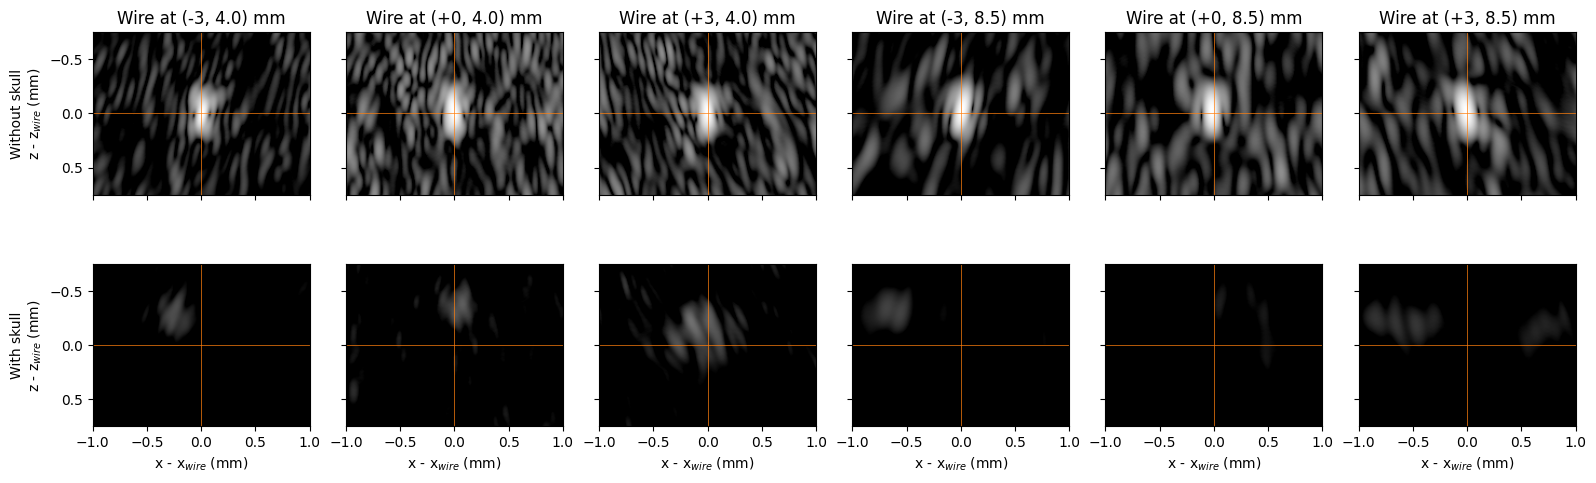

In [15]:
fig, axes = plt.subplots(2, len(wires), figsize=(16, 5.5), sharex="col", sharey="row")
for i, (wx, wz) in enumerate(wires):
    peak = patches["no skull"][i][2].max()
    for row, name in enumerate(patches):
        xp, zp, env = patches[name][i]
        ax = axes[row, i]
        ax.imshow(20 * np.log10(env / peak + 1e-6), cmap="gray", vmin=-30, vmax=0,
                  extent=[(xp[0] - wx) * 1e3, (xp[-1] - wx) * 1e3, (zp[-1] - wz) * 1e3, (zp[0] - wz) * 1e3])
        ax.axhline(0, color="C1", linewidth=0.5)
        ax.axvline(0, color="C1", linewidth=0.5)
    axes[0, i].set_title(f"Wire at ({wx * 1e3:+.0f}, {wz * 1e3:.1f}) mm")
    axes[1, i].set_xlabel("x - x$_{wire}$ (mm)")
axes[0, 0].set_ylabel("Without skull\nz - z$_{wire}$ (mm)")
axes[1, 0].set_ylabel("With skull\nz - z$_{wire}$ (mm)")
plt.tight_layout()
plt.show()

In [16]:
def cyst_contrast(env, cx, cz, r):
    """Mean intensity inside a cyst relative to a ring of speckle around it, in dB."""
    d = np.hypot(x_img[None, :] - cx, z_img[:, None] - cz)
    return 10 * np.log10((env[d < 0.7 * r] ** 2).mean() / (env[(d > 1.3 * r) & (d < 2 * r)] ** 2).mean())


for name in ["Notebook 2 model", "k-Wave, no skull", "k-Wave, with skull"]:
    print(f"{name:20s} cyst contrast: " + ", ".join(f"{cyst_contrast(envelopes[name], *cy):.0f} dB" for cy in cysts))

Notebook 2 model     cyst contrast: -13 dB, -13 dB, -13 dB, -8 dB
k-Wave, no skull     cyst contrast: -12 dB, -14 dB, -15 dB, -9 dB
k-Wave, with skull   cyst contrast: 1 dB, -2 dB, -2 dB, -5 dB


Without the skull, every wire is where it should be, to within 20 μm. Behind the skull:

* Every wire is around 20 dB dimmer, and 0.2-0.4 mm too shallow: sound crosses the bone almost twice as fast as the tissue, so the echoes come back early.
* Some wires also move sideways, by up to 0.7 mm, and spread out to several times their width; others barely change. It depends on the shape of the bone above each wire.
* The cysts lose almost all of their contrast, filled in by echoes that are put in the wrong place.

The reason is the assumption baked into delay-and-sum: every echo travels at 1540 m/s along a straight line. The skull breaks it in two ways. The extra speed in the bone shifts the arrival times by an amount that depends on how much bone each path crosses, so the echoes from a point no longer add up in phase across the probe. And at the skull's surfaces, rays refract, so the paths aren't straight. No single speed of sound fixes this, because the error differs from one element to the next.

In practice, people deal with this in a few ways:

* **Avoid the skull.** In rats and primates, fUS usually images through an opening in the skull: Griggs et al. (2025), the data of notebook 5, placed the probe directly on the dura. In humans, fUS has been done during neurosurgery and through an acoustically transparent skull implant (Rabut et al., 2024).
* **Use thin skulls and lower frequencies.** Through the thin skull of mice and young rats, fUS works without surgery (Tiran et al., 2017). Lower frequencies suffer less, at the cost of resolution.
* **Correct the delays.** If you know the speed of sound along each path, for example from a CT scan of the skull, you can compute the right delays; in general this requires the kind of full-wave or ray-tracing model we just ran. Without a skull model, *autofocusing* methods estimate a map of the speed of sound from the data itself, for example by adjusting it until the image is as sharp as possible (Simson et al., 2023).

# GPU beamforming

Our simulation gave us one compound image. A Power Doppler image needs hundreds: Griggs et al. (2025) acquired compound images at 500 per second and combined 250 of them into each Power Doppler image. To keep up in real time, a beamformer must form hundreds of images per second, which is where GPUs come in. We'll look at two GPU beamformers: vbeam and mach.

## vbeam

[vbeam](https://github.com/magnusdk/vbeam) (Kvalevåg et al., 2023) is built around a single function, `signal_for_point`, that computes the contribution of one transmit and one receiving element to one pixel: compute the delay, interpolate the channel data at that delay, and correct the phase. Everything else is composition: vbeam vectorizes that function over pixels, elements, transmits and frames with JAX's `vmap`, sums over the dimensions you ask for, and compiles the whole thing with `jit`. The same code runs on a CPU or a GPU, and because it's written in JAX, it's differentiable, which is what autofocusing methods use to optimize the speed of sound by gradient descent.

Each ingredient of `signal_for_point` is an object you can swap: the transmitted wavefront (plane, focused, diverging), the interpolation, the apodization, even the speed of sound. To check vbeam against our code, we choose the ingredients that match our Numba delay-and-sum: plane waves, nearest-neighbor interpolation and no apodization.

In [17]:
from spekk import Spec
from vbeam.apodization import (
    Hamming,
    NoApodization,
    PlaneWaveReceiveApodization,
    PlaneWaveTransmitApodization,
    TxRxApodization,
)
from vbeam.beamformers import get_das_beamformer
from vbeam.core import ElementGeometry, WaveData
from vbeam.data_importers import SignalForPointSetup
from vbeam.fastmath import backend_manager
from vbeam.interpolation import FastInterpLinspace, NearestInterpolation
from vbeam.scan import linear_scan
from vbeam.wavefront import PlaneWavefront, ReflectedWavefront

backend_manager.active_backend = "jax"


def vbeam_setup(iq, interpolation=None, apodization=None):
    """A vbeam setup for our plane-wave data. iq: (transmits, receivers, samples), or (frames, transmits, ...)."""
    zeros = np.zeros(n_elem)
    dims = ["transmits", "receivers", "signal_time"]
    return SignalForPointSetup(
        sender=ElementGeometry(np.zeros(3), 0.0, 0.0),  # plane waves pass through x = 0, z = 0 at t = 0
        point_position=None,
        receiver=ElementGeometry(np.stack([elem_pos, zeros, zeros], axis=-1), zeros, zeros),
        signal=iq.astype(np.complex64),
        transmitted_wavefront=PlaneWavefront(),
        reflected_wavefront=ReflectedWavefront(),
        speed_of_sound=c0,
        wave_data=WaveData(azimuth=betas, elevation=np.zeros(len(betas)), t0=np.zeros(len(betas))),
        interpolate=interpolation or NearestInterpolation(times[0], times[1] - times[0], len(times)),
        modulation_frequency=f0,
        apodization=apodization or NoApodization(),
        spec=Spec({"signal": ["frames"] * (iq.ndim == 4) + dims, "receiver": ["receivers"],
                   "point_position": ["points"], "wave_data": ["transmits"]}),
        scan=linear_scan(x_img, z_img),
    )


def vbeam_beamformer(setup):
    return jax.jit(get_das_beamformer(setup, compensate_for_apodization_overlap=False, log_compress=False,
                                      scan_convert=False))


setup = vbeam_setup(iq_tissue)
beamformer = vbeam_beamformer(setup)
img_vbeam = np.asarray(beamformer(**setup.data)).T / n_elem  # vbeam returns (x, z) and sums over elements

# Our images used time-gain compensation; compare without it
img_numba = beamform_das_vectorized(iq_tissue, times, elem_pos, x_img, z_img, c0, betas, omega)
err = np.linalg.norm(img_vbeam - img_numba) / np.linalg.norm(img_numba)
print(f"vbeam vs. Numba delay-and-sum: relative difference {err:.1e}")

vbeam vs. Numba delay-and-sum: relative difference 1.7e-04


The two agree to within 0.02%. vbeam computes in single precision (float32) by default, so a few delays round to the neighboring sample; in double precision, they agree to 14 digits. One detail mattered for this match: our Numba code clamps out-of-range delays to the first or last sample, while vbeam treats them as zero. That's why we padded the channel data with zeros up to the longest delay in the image.

Matching our code is a test, not the point. Real beamformers interpolate between samples, and *apodize*: they weight each element by how well it can see a pixel, rather than adding them all equally. Here's the recipe vbeam uses by default when it imports plane-wave datasets, such as the PICMUS benchmark: linear interpolation, a Hamming-weighted receive aperture that widens with depth (we set its f-number, the ratio of depth to aperture width, to 1), and transmit apodization that ignores pixels outside the insonified region.

Nearest neighbor, all elements equal: cyst contrast -13 dB, -14 dB, -15 dB, -10 dB
Linear interpolation, apodization (f/1): cyst contrast -16 dB, -18 dB, -23 dB, -20 dB


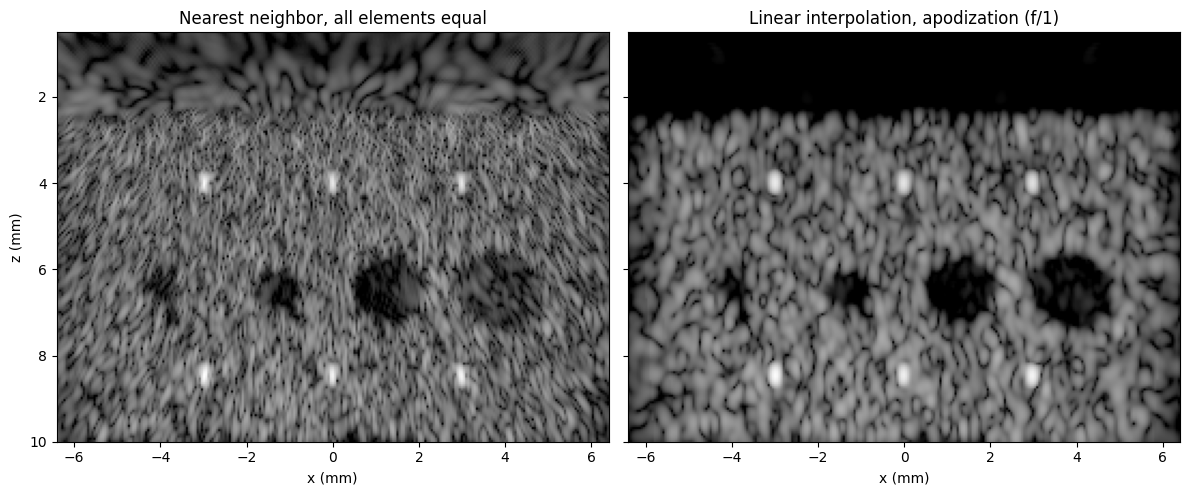

In [18]:
array_bounds = (np.array([elem_pos[0], 0.0, 0.0]), np.array([elem_pos[-1], 0.0, 0.0]))
setup_apod = vbeam_setup(
    iq_tissue,
    interpolation=FastInterpLinspace(times[0], times[1] - times[0], len(times)),
    apodization=TxRxApodization(transmit=PlaneWaveTransmitApodization(array_bounds),
                                receive=PlaneWaveReceiveApodization(Hamming(), 1.0)),
)
img_apod = np.asarray(vbeam_beamformer(setup_apod)(**setup_apod.data)).T

tgc = np.exp(2 * alpha * z_img)[:, None]  # approximate time-gain compensation, for display
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, img, title in [(axes[0], img_numba, "Nearest neighbor, all elements equal"),
                       (axes[1], img_apod, "Linear interpolation, apodization (f/1)")]:
    env = np.abs(img) * tgc / np.median(np.abs(img[speckle]) * tgc[speckle])
    ax.imshow(20 * np.log10(env + 1e-6), extent=img_extent, cmap="gray", vmin=-20, vmax=30)
    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    print(f"{title}: cyst contrast " + ", ".join(f"{cyst_contrast(env, *cy):.0f} dB" for cy in cysts))
axes[0].set_ylabel("z (mm)")
plt.tight_layout()
plt.show()

Apodization trades some resolution (the speckle grain gets coarser) for lower side lobes: the cysts get much darker, because less energy leaks into them from the surrounding speckle.

## mach

[mach](https://github.com/Forest-Neurotech/mach) (Guan et al., 2026) takes the opposite approach to vbeam: rather than composing a general beamformer from small functions, it is a single CUDA kernel, hand-tuned for the delay-and-sum of large ensembles of frames, as in functional ultrasound. It runs only on NVIDIA GPUs under Linux, so on a laptop without one, the next cell skips it. On Colab with a GPU, it beamforms the same data with matching settings: all elements, no apodization, nearest-neighbor interpolation. mach sums over elements, and computes in float32.

In [19]:
try:
    from mach import kernel as mach_kernel

    HAS_MACH = GPU
except ImportError:  # mach ships wheels for Linux + CUDA only
    HAS_MACH = False

if HAS_MACH:
    Xi, Zi = np.meshgrid(x_img, z_img)
    mach_points = cp.asarray(np.stack([Xi.ravel(), np.zeros(Xi.size), Zi.ravel()], axis=-1), dtype=cp.float32)
    mach_elements = cp.asarray(np.stack([elem_pos, np.zeros(n_elem), np.zeros(n_elem)], axis=-1), dtype=cp.float32)
    mach_tx = cp.asarray((np.sin(betas)[:, None] * Xi.ravel() + np.cos(betas)[:, None] * Zi.ravel()) / c0,
                         dtype=cp.float32)

    def beamform_mach(iq_frames):
        """iq_frames: (frames, transmits, receivers, samples). Returns (pixels, frames) on the GPU."""
        data = cp.ascontiguousarray(cp.asarray(iq_frames, dtype=cp.complex64).transpose(1, 2, 3, 0))  # (transmits, receivers, samples, frames)
        out = cp.zeros((mach_points.shape[0], iq_frames.shape[0]), dtype=cp.complex64)
        for m in range(len(betas)):  # mach adds each transmit into `out`
            mach_kernel.beamform(
                data[m], mach_elements, mach_points, mach_tx[m], out=out,
                rx_start_s=float(times[0]), sampling_freq_hz=fs, sound_speed_m_s=c0, modulation_freq_hz=f0,
                f_number=1e-3, tukey_alpha=0.0,  # a tiny f-number opens the full aperture
                interp_type=mach_kernel.InterpolationType.NearestNeighbor,
            )
        return out

    img_mach = cp.asnumpy(beamform_mach(iq_tissue[None]))[:, 0].reshape(len(z_img), len(x_img)) / n_elem
    err = np.linalg.norm(img_mach - img_numba) / np.linalg.norm(img_numba)
    print(f"mach vs. Numba delay-and-sum: relative difference {err:.1e}")
else:
    print("mach needs an NVIDIA GPU under Linux: skipping. Run this notebook on Colab with a GPU to try it.")

mach vs. Numba delay-and-sum: relative difference 1.7e-04


## How fast?

To benchmark, we beamform an ensemble of frames, as you would for Power Doppler. We'll repeat our simulated frame 20 times; the timing doesn't depend on the content. Along with the Numba code and the GPU beamformers, we include one more CPU approach, which follows from notebook 2's "DAS as a matrix operation": because the delays are the same for every frame, delay-and-sum is a fixed linear map from channel data to pixels. The helper module can store it once as a sparse matrix, which we then apply to all frames in a single matrix product.

In [20]:
n_frames = 20
ensemble = np.repeat(iq_tissue[None], n_frames, axis=0)  # (frames, transmits, receivers, samples)
rates = {}


def frames_per_second(beamform_all, label, warm_up=False):
    if warm_up:  # compile, allocate
        beamform_all()
    t1 = time.perf_counter()
    beamform_all()
    rates[label] = n_frames / (time.perf_counter() - t1)
    print(f"{label}: {rates[label]:.1f} frames/s")


frames_per_second(lambda: [beamform_das_vectorized(f, times, elem_pos, x_img, z_img, c0, betas, omega) for f in ensemble],
                  "Numba, frame by frame (CPU)")

t1 = time.perf_counter()
das_matrix = build_das_sparse_matrix(times, elem_pos, x_img, z_img, c0, betas, omega)
print(f"Sparse matrix: {das_matrix.nnz / 1e6:.0f} M non-zeros, built in {time.perf_counter() - t1:.0f} s")
flat = ensemble.reshape(n_frames, -1).T.copy()
frames_per_second(lambda: das_matrix @ flat, "Sparse matrix, all frames (CPU)")
del das_matrix

chunk = 5  # frames per call, to bound memory
setup_frames = vbeam_setup(ensemble[:chunk])
beamformer_frames = vbeam_beamformer(setup_frames)
signal_chunks = [jax.device_put(ensemble[i : i + chunk].astype(np.complex64)) for i in range(0, n_frames, chunk)]
kernel_data = {k: v for k, v in setup_frames.data.items() if k != "signal"}
frames_per_second(lambda: [beamformer_frames(signal=s, **kernel_data).block_until_ready() for s in signal_chunks],
                  f"vbeam ({jax.devices()[0].platform.upper()})", warm_up=True)

if HAS_MACH:
    ensemble_gpu = cp.asarray(ensemble, dtype=cp.complex64)

    def beamform_mach_all():
        beamform_mach(ensemble_gpu)
        cp.cuda.Device().synchronize()

    frames_per_second(beamform_mach_all, "mach (GPU)", warm_up=True)

Numba, frame by frame (CPU): 0.8 frames/s
Sparse matrix: 31 M non-zeros, built in 2 s
Sparse matrix, all frames (CPU): 5.4 frames/s
vbeam (GPU): 153.0 frames/s
mach (GPU): 2093.3 frames/s


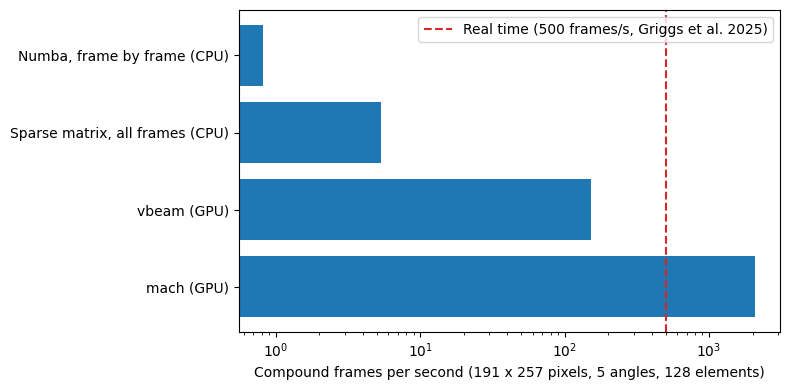

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(list(rates), list(rates.values()), color="C0")
ax.axvline(500, color="C3", linestyle="--", label="Real time (500 frames/s, Griggs et al. 2025)")
ax.set_xscale("log")
ax.set_xlabel(f"Compound frames per second ({len(z_img)} x {len(x_img)} pixels, {len(betas)} angles, {n_elem} elements)")
ax.invert_yaxis()
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

On a CPU, all approaches are about 100 times too slow for real time, or worse: fine for analyzing data offline, as in notebooks 3-5, but not for a live display. The sparse matrix wins on the CPU because it does the geometry once, and then only multiplies and adds. The work is embarrassingly parallel (every pixel, element and frame is independent), and the channel data for an ensemble fits in GPU memory, which is why ultrafast scanners beamform on GPUs. On Colab's T4 GPU, vbeam forms about 150 frames per second, and mach about 2,000, four times faster than real time.

# A map of the ecosystem

Here's where the tools we've used, and a few others, fit in. All are open source.

| Stage | Tool | What it is | Reach for it when |
|---|---|---|---|
| Simulation | [k-Wave](http://www.k-wave.org/) / [k-wave-python](https://github.com/waltsims/k-wave-python) | Pseudospectral full-wave solver (MATLAB, Python; C++/CUDA binaries) | Heterogeneous media, e.g. skull; transcranial focusing |
| | [j-Wave](https://github.com/ucl-bug/jwave) | Pseudospectral solver in JAX, differentiable | Optimizing a medium or a transmit by gradient descent |
| | [Stride](https://github.com/trustimaging/stride) and [NDK](https://github.com/agencyenterprise/neurotechdevkit) | Finite-difference solver built on Devito, and a toolkit for transcranial focused ultrasound built on it | Ultrasound tomography; planning focused ultrasound through the skull |
| | [PyMUST](https://github.com/creatis-ULTIM/PyMUST) | Python port of the MUST toolbox: fast linear simulator (SIMUS) and beamformers | Fast simulations in soft tissue, like notebook 2's but with a more complete transducer model |
| Beamforming | [vbeam](https://github.com/magnusdk/vbeam) | Modular, differentiable beamformer in JAX (CPU/GPU) | Prototyping beamformers, autofocusing, research on image formation |
| | [mach](https://github.com/Forest-Neurotech/mach) | Delay-and-sum as one optimized CUDA kernel | Beamforming large ensembles for Doppler, as fast as possible |
| | [ultraspy](https://ultraspy.readthedocs.io/) | Beamformers (delay-and-sum and adaptive variants), Doppler processing and image quality metrics, on CPU or GPU | Comparing beamforming algorithms, with readable documentation (linked in the README) |
| Real-time pipelines | [FAST](https://github.com/smistad/FAST) (Python: pyFAST) | Framework for streaming, processing and visualizing medical images on CPUs and GPUs, with neural network inference | Live processing of data streamed from a scanner |
| fUS analysis | [PyfUS](https://github.com/OpenfUS/PyfUS) | Registration, signal processing and visualization of fUS data (OpenfUS, Urban lab) | Brain-wide fUS datasets, registered to an atlas |

A rule of thumb: in soft tissue, a linear model like notebook 2's (or PyMUST) is orders of magnitude cheaper than a full-wave solver, and as we saw, it's accurate. Reach for k-Wave or Stride when the medium has strong contrasts, like bone or air, or when you need what happens between the echoes: reverberation, refraction, nonlinear propagation.

# Caveats

* **2D.** A 3D version of this simulation would have hundreds of times more grid points, and the skull's effect is truly 3D. On a GPU, k-Wave handles 3D grids of this size, but not in a few minutes on a laptop.
* **The skull model is gentle.** Real bone also carries shear waves, absorbs much more than tissue, and has internal structure (two dense tables around a porous layer in thicker skulls), all of which make things worse.
* **No Doppler.** We simulated one frame. A Power Doppler image needs ~250 compound frames with moving scatterers, i.e. over a thousand full-wave simulations: about a day on an 8-core CPU. That's why Doppler simulations usually use linear models like notebook 3's, sometimes combined with a full-wave model of the skull.
* **No noise.** Real channel data has electronic noise, which makes the faint signals behind the skull even harder to see.
* **CPU and GPU runs differ slightly.** Without a GPU, k-Wave runs its C++ solver; with one, its NumPy/CuPy solver. They agree on where everything is, but not to the last decibel: behind the skull, the wires' brightness differs by 2-3 dB between the two.

# Exercises

* Make the skull flat (constant thickness). Do the wires still move sideways? Can a single, adjusted speed of sound in the beamformer bring them back into focus?
* Make the skull thicker, or the transmit frequency lower (remember to keep at least ~3 grid points per wavelength). How does the damage scale?
* Use vbeam's `HeterogeneousSpeedOfSound` to beamform with the true speed-of-sound map. vbeam's documentation warns that it averages the speed of sound along straight lines, which isn't right for plane waves: how much of the image does it recover?
* Simulate a short Doppler ensemble with k-Wave: move the scatterers of a "vessel" between frames, as in notebook 3, and form a Power Doppler image through the skull. Start with a handful of frames and a single angle.
* Benchmark the beamformers as a function of image size and number of frames. Where does each one spend its time?

# References

* Treeby & Cox 2010. [k-Wave: MATLAB toolbox for the simulation and reconstruction of photoacoustic wave fields](https://doi.org/10.1117/1.3360308). *Journal of Biomedical Optics*.
* Kvalevåg et al. 2023. [vbeam: a fast and differentiable beamformer for optimizing ultrasound imaging](https://doi.org/10.1109/IUS51837.2023.10307255). *IEEE International Ultrasonics Symposium*.
* Guan et al. 2026. [mach: ultrafast ultrasound beamforming](https://doi.org/10.1117/1.JMI.13.6.062203). *Journal of Medical Imaging*.
* Griggs et al. 2025. [Functional ultrasound neuroimaging reveals mesoscopic organization of saccades in the lateral intraparietal area](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC12488887/). *Nature Communications*.
* Rabut et al. 2024. [Functional ultrasound imaging of human brain activity through an acoustically transparent cranial window](https://doi.org/10.1126/scitranslmed.adj3143). *Science Translational Medicine*.
* Tiran et al. 2017. [Transcranial functional ultrasound imaging in freely moving awake mice and anesthetized young rats without contrast agent](https://doi.org/10.1016/j.ultrasmedbio.2017.03.011). *Ultrasound in Medicine & Biology*.
* Simson et al. 2023. [Differentiable beamforming for ultrasound autofocusing](https://doi.org/10.1007/978-3-031-43999-5_41). *MICCAI*.
* Perrot et al. 2021. [So you think you can DAS? A viewpoint on delay-and-sum beamforming](https://arxiv.org/abs/2007.11960). *Ultrasonics*.